In [1]:
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import Video

from scipy.stats import multivariate_normal, chi2, gamma
from scipy.special import ndtr

from utils import color_cycle

# Lecture 1: Monte Carlo methods and spin models

1. Learning as inference; high dimensionality, self-averaging and concentration
2. Sampling: uniform sampling, entropy and the typical set
3. Importance and rejection sampling (bonus: the curse of dimensionality)
4. Markov processes: stationarity and detailed balance
5. Markov chain Monte Carlo: Metropolis-Hastings and Gibbs sampling
6. Spin models: exponential families; MCMC for the Ising model, energy and magnetization
7. A quick look at optimization: travelling salesman, binary perceptron, simulated annealing

MacKay, **Chapter 29** (Monte Carlo methods), **Chapter 31** (Ising models) and the section on simulated annealing of **Chapter 30**; **Chapter 4** for the typical set. Intro follows the first part of **Chapter 41**.

_Recommended readings_:

* **Chapter 27** of [Bayesian Reasoning and Machine Learning](http://web4.cs.ucl.ac.uk/staff/D.Barber/pmwiki/pmwiki.php?n=Brml.HomePage) by David Barber
* [Timothy Budd](https://hef.ru.nl/~tbudd/)'s course on [Monte Carlo techniques](https://hef.ru.nl/~tbudd/mct/intro.html)

## Intro: learning as inference and high dimensionality

MacKay, first part of **Chapter 41**.

_Recommended readings and watching_:

* [Understanding deep learning is also a job for physicists](https://www.nature.com/articles/s41567-020-0929-2) by [Lenka Zdeborová](https://people.epfl.ch/lenka.zdeborova/?lang=en)
* [A new view on independence](https://projecteuclid.org/journals/annals-of-probability/volume-24/issue-1/A-new-look-at-independence/10.1214/aop/1042644705.full) by [Michel Talagrand](https://en.wikipedia.org/wiki/Michel_Talagrand)
* A free online course on [High Dimensional Probability](https://www.math.uci.edu/~rvershyn/teaching/hdp/hdp.html) by [Roman Vershynin](https://www.math.uci.edu/~rvershyn/)
* A free online course on [High Dimensional Analysis: Random Matrices and Machine Learning](https://www.youtube.com/playlist?list=PLY11JnnnTUCabY4nc0hKptrd5qEWtLoo2) by [Roland Speicher](https://www.uni-saarland.de/lehrstuhl/speicher/roland-speicher.html)

### Learning as an inference problem

**Data set**:
$$D=\{x^\mu,t^\mu\}$$

with $t^\mu=\pm 1$ and $\mu=1,\ldots,P$.

**Conditional model** (probability of label $t^\mu$ given $x^\mu$):
$$p(t^\mu|x^\mu,w)=\sigma(t^\mu w\cdot x^\mu)$$

**Likelihood**:
$$p(D|w)=\prod_\mu p(t^\mu|x^\mu,w)=e^{-\mathcal{E}(w)}\qquad \mathcal{E}(w)=-\sum_\mu \log p(t^\mu|x^\mu,w)$$

**Prior**:
$$p(w)=\frac{e^{-\alpha R(w)}}{Z_w(\alpha)}\qquad R(w)=\frac{1}{2}\sum_i w_i^2$$

**Posterior**:
$$p(w|D)=\frac{p(D|w)p(w)}{p(D)} \propto e^{-L(w)}$$
with
$$L(w)=\mathcal{E}(w)+\alpha R(w)$$

### ML versus Bayesian approach

In neural network learning one typically computes the **maximum likelihood** or **maximum posterior** solution.

For new test point $x^\text{test}$, using an ML approach:
$$D \rightarrow w_\mathsf{ml}$$
$$p(t|x^\text{test},w_\mathsf{ml})$$

Bayesian approach requires integration over multiple solutions:
$$D \rightarrow p(w|D)$$
$$p(t|x^\text{test})=\int dw p(w|D) p(t|x^\text{test},w)$$

### But are high dimensions always bad?

#### Self-averaging / Concentration: the bliss of high dimension

**Self-averaging**: *Well-behaved* observables in learning problems have negligible fluctuations across random realizations of problem instances

**Concentration**: *Well-behaved* functions in high dimensions are almost anywhere constant.

# Sampling

## The problem

In many machine learning problems one needs to estimate high dimensional integrals:

1.  Estimate expected parameter values in the posterior of a Bayesian learning problem:
    $$p(\theta|D)=\frac{p(D|\theta) p(\theta)}{p(D)}\qquad \mathbb{E}\theta =\int d\theta \theta p(\theta|D)$$

2.  Estimate the *evidence* for model selection
    $$p(D|\mathcal{H}_i)=\int d\theta p(D|\theta,\mathcal{H}_i) p(\theta|\mathcal{H}_i)$$

3.  Computing statistics in graphical models $p(x_1,\ldots,x_n)=\prod_{i=1}^n p_i(x_i|x_{\text{Pa}(i)})$
    $$p(x_1,x_2)=\sum_{x_3,\ldots,x_n} p(x_1,\ldots,x_n)$$

Denote $p(x)=\frac{p^*(x)}{Z}$ the probability distribution of interest with $Z=\int dx p^*(x)$.
We can assume that $p^*(x)$ is easily evaluated for any $x$, but $Z$ is hard to evaluate.

## The problem with uniform sampling

Suppose we're only allowed to produce $N$ points $x^r$ in the support of $p^*$. The best way to choose them is to extract them with probability $p(x)=p^*(x)/Z$:
$$\hat{\Phi}=\frac{1}{N}\sum_{r=1}^N \phi(x^r)\qquad x^r \sim p(x)$$
$\hat{\Phi}$ is a random variable (each time we generate $N$ samples we get a different outcome). If we draw the $x^r$ independently we have

$$\mathbb{E} \hat{\Phi}=\frac{1}{N}\sum_{r=1}^N\sum_{x^r} p(x^r)\phi(x^r)=\Phi$$

The estimator $\hat{\Phi}$ is **unbiased**.

The variance in $\hat{\Phi}$ decreases with the number of samples $N$. Indeed, for a sum of independent random variables $X=\sum_i X_i$ is a sum of independent random variables, the variance of $X$ is the sum of the variances of each $X_i$. Therefore:

$$\mathrm{Var} \left[\hat{\Phi}\right] = N \mathrm{Var} \left[\frac{\phi}{N}\right] =\frac{1}{N}\mathrm{Var} \left[\phi\right] \qquad \mathrm{Var} \left[\phi\right] = \sum_x p(x) (\phi(x) - \Phi)^2$$

Thus,
$$\hat{\Phi}=\Phi + \mathcal{O}\left(\frac{1}{\sqrt{N}}\right)$$

The accuracy does not depend on the dimension of the problem. But sampling from $p$ is very hard.

## Entropy and the typical set

#### A simple experiment with $N$ coins

In [2]:
# toss N coins with increasing N
num_N = 20
num_samples = 100

Ns = np.logspace(1, 6, num_N, dtype=int)
fraction_heads = np.zeros((num_N, num_samples))

for i, N in enumerate(Ns):
    draws = 1 * (np.random.rand(num_samples, N) <= 0.5)
    fraction_heads[i] = draws.sum(1) / N

The following plot shows a well known result:

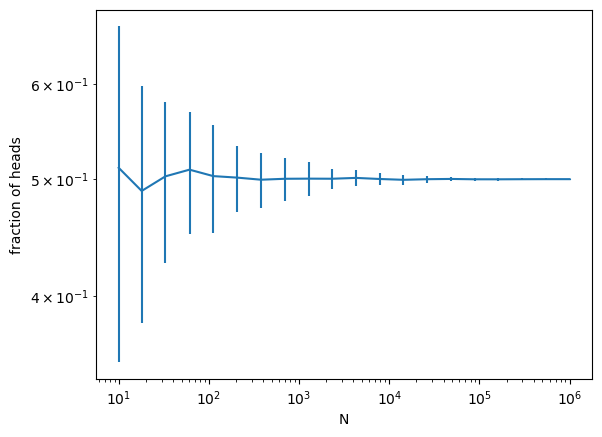

In [3]:
plt.errorbar(Ns, y=fraction_heads.mean(1), yerr=fraction_heads.std(1));
plt.xlabel('N')
plt.ylabel('fraction of heads');
plt.yscale('log')
plt.xscale('log')

#### Uniform sampling of a biased coin

Let's try to sample from a non-uniform distribution using a uniform proposal. The simplest non-uniform distribution for discrete variables is a set of Bernoulli distributed events with $p\neq0.5$. Let us take $p=0.2$:

$$p\left(x\right)=\prod_{i}p^{x_{i}}\left(1-p\right)^{1-x_{i}}=e^{\sum_{i}\left(x_{i}\log p+\left(1-x_{i}\right)\log\left(1-p\right)\right)}$$

and use

$$
\hat{\Phi}=\frac{\sum_{r=1}^{N}\phi\left(x^{r}\right)p\left(x^{r}\right)}{\sum_{r=1}^{N}p\left(x^{r}\right)}
$$

/tmp/ipykernel_37884/1018345848.py:13: RuntimeWarning: invalid value encountered in scalar divide
  fraction_heads_av[i] = (draws.sum(1) / n * px).sum() / px.sum()


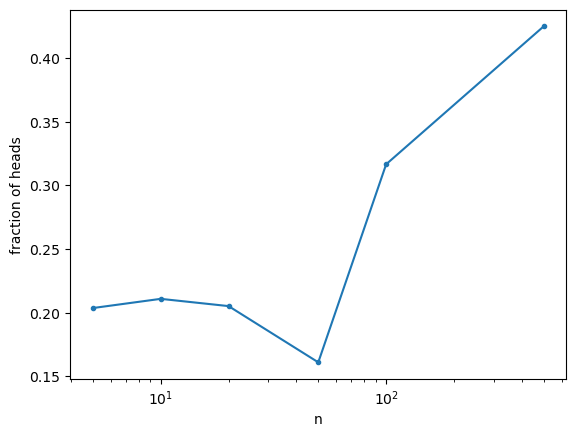

In [4]:
# toss n coins with increasing n
p = 0.2
N = 10000

ns = [5, 10, 20, 50, 100, 500, 1000]
num_n = len(ns)
fraction_heads_av = np.zeros(num_n)

for i, n in enumerate(ns):
    draws = 1 * (np.random.rand(N, n) <= 0.5)
    logpx = (draws * np.log2(p) + (1-draws) * np.log2(1-p)).sum(1)
    px = 2**logpx
    fraction_heads_av[i] = (draws.sum(1) / n * px).sum() / px.sum()

plt.plot(ns, fraction_heads_av, '.-');
plt.xlabel('n')
plt.ylabel('fraction of heads');
plt.xscale('log')

Our interpretation is the following: of all the $2^n$ configurations of outcomes, the ones where the fraction of heads is close to $1/2$ dominate (in fact they **exponentially dominate**) the counting over a uniform distribution, this being more and more evident as $n$ grows. Indeed, the number of heads has a binomial distribution with mean $np$ and variance $np(1-p)$: the relative scaling of the standard deviation wrt the mean is an indication of concentration.

#### Sampling and entropy

Draw long sequence of $N$ states of $n$ binary variables (e.g. $n$ coins) from a distribution $p(x)$:

$$x^1,x^2, \ldots, x^N$$

The probability of the sequence is
$$p(x^1,x^2\ldots, x^N)=p(x^1)p(x^2)\ldots p(x^N)= \prod_x p(x)^{N(x)}$$
with $N(x)\approx p(x) N$ the number of times the value $x$ occurs in the string. Thus we have:
$$p(x^1,x^2\ldots, x^N)\approx \prod_x p(x)^{p(x)N} =\left(2^{- H}\right)^N$$
with $H=-\sum_x p_x \log_2 p_x$ the entropy of the distribution. Equivalently
$$\prod_{i}p\left(x_{i}\right)=2^{N\frac{\sum_{i}\log p\left(x_{i}\right)}{N}}\approx2^{-NH}$$

Thus, in the large $N$ limit all **typical** strings have the same probability $2^{-NH}$ and all other **non-typical** strings have probability zero.

The formula suggests that *on average* for a single sample, there are typical samples with probability $2^{-H}$ and non-typical samples with probability zero.

Denote $T$ the set of typical samples. The number of typical samples is thus $|T|\approx 2^{H}$.

The **typical set** should be compared to the total number of states $2^n$. The volume fraction is
$$2^{H-n}$$
If we sample states $x$ uniformly at random, the probability to hit an element of the typical set is $2^{H-n}$.
Thus, one needs on the order of $N_\text{min}=2^{n-H}$ samples to hit the typical set once and therefore the
number of samples
$$N\gg N_\text{min}=2^{n-H}$$

For $n$ binary spins $0\le H \le n$.

#### Typical set in coin flipping

Let us look at a histogram of $-\log(p(x))$ with $x$ a sequence of $N$ independent tosses of a biased coin with $p=0.1$:

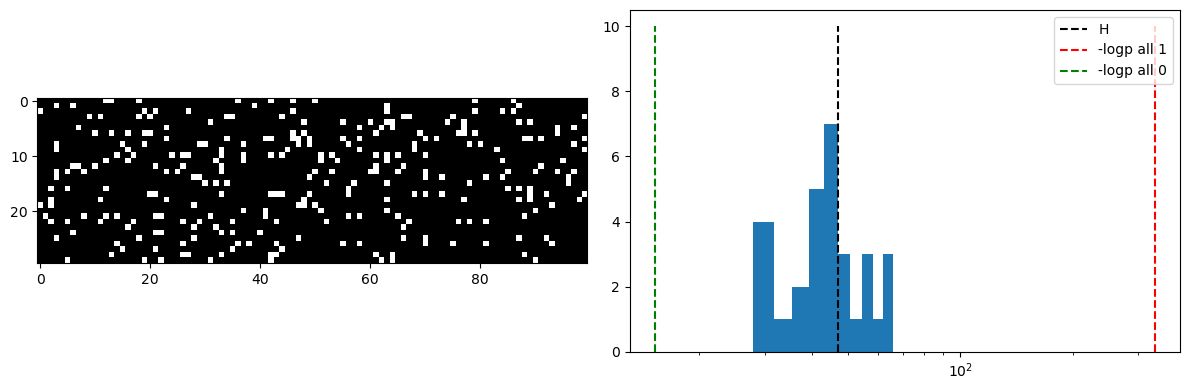

In [5]:
N = 100
num_samples = 30

p = 0.1
draws = 1 * (np.random.rand(num_samples, N) <= p)
logpx = (draws * np.log2(p) + (1-draws) * np.log2(1-p)).sum(1)

H = -N * (p * np.log2(p) + (1-p) * np.log2(1-p))

logp_all1 = N * np.log2(p)
logp_all0 = N * np.log2(1-p)

plt.figure(figsize=(12,4))

plt.subplot(121)
plt.imshow(draws, cmap='gray');

plt.subplot(122)
plt.hist(-logpx);
plt.vlines(x=H, ymin=0, ymax=10, ls='--', color='black', label='H');
plt.vlines(x=-logp_all1, ymin=0, ymax=10, ls='--', color='red', label='-logp all 1');
plt.vlines(x=-logp_all0, ymin=0, ymax=10, ls='--', color='green', label='-logp all 0');
plt.xscale('log')
plt.legend();

plt.tight_layout();

#### Conclusion: Uniform sampling only works for uniform distributions.

## Importance and rejection sampling

### Importance sampling

Let us write
$$\Phi=\int dxp\left(x\right)\phi\left(x\right)=\int dxq\left(x\right)\frac{p\left(x\right)}{q\left(x\right)}\phi\left(x\right)$$

i.e. we sample $x^1,\ldots,x^R$ from a distribution $q(x)$ and estimate
$$\hat{\Phi}=\frac{1}{R}\sum_{r=1}^R w(x^r)\phi(x^r)\qquad w(x)=\frac{p(x)}{q(x)}$$
where $w(x)$ are the **importance weights**. We want $q$ to be
* better than uniform;
* easy to sample from.

For instance, a (spherical) Gaussian:
$$Q^*(x)\propto \exp\left(-\frac{1}{2}\sum_i x_i^2\right)$$

Consider simple 1-d sampling problem. Given $p(x)$, compute
$$\Phi=\mathrm{Prob}(x<0)=\int_{-\infty}^\infty \phi(x) p(x)dx$$
with $\phi(x)=1$ if $x\le0$ and zero otherwise.

**Naive method**: generate $N$ samples $X_i\sim p$
$$\hat{\Phi}=\frac{1}{N}\sum_{i=1}^N \phi(X_i)$$

**Importance sampling**: consider another distribution $q(x)$. Then
$$\Phi=\mathrm{Prob}(x<0)=\int_{-\infty}^\infty \phi(x) \frac{p(x)}{q(x)}q(x) dx$$

Generate $N$ samples $X_i\sim q$
$$\hat{\Phi}=\frac{1}{N}\sum_{i=1}^N \phi(X_i)\frac{p(X_i)}{q(X_i)}$$

#### A simple example of why you would want to use importance sampling

Let's compute the probability of a normal random variable $X$ to be greater than a value `thresh` using both the original density $p$ and a broader candidate $q$.

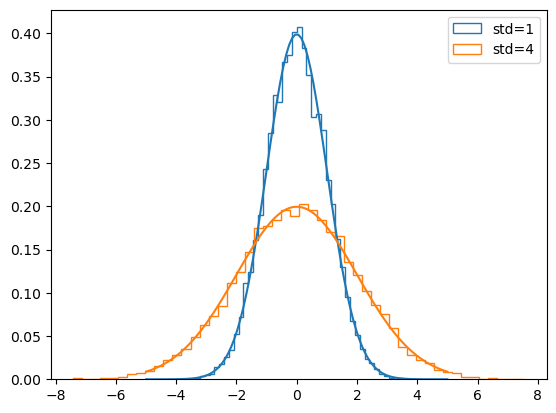

In [6]:
thresh = 4
num_sample = 10000
num_trials = 100
pthres_1 = np.zeros(num_trials)
pthres_4 = np.zeros(num_trials)

for trial in range(num_trials):
    normal_1 = multivariate_normal(0, 1)
    normal_4 = multivariate_normal(0, 4)
    sample_1 = normal_1.rvs(num_sample)
    sample_4 = normal_4.rvs(num_sample)
    pthres_1[trial] = (sample_1 > thresh).mean()
    pthres_4[trial] = (normal_1.pdf(sample_4) / normal_4.pdf(sample_4) * (sample_4 > thresh)).mean()

# visualize a single sample
xs = np.linspace(-5, 5, 100)
plt.hist(sample_1, bins=50, histtype="step", density=True, label='std=1');
plt.hist(sample_4, bins=50, histtype="step", density=True, label='std=4');
plt.plot(xs, normal_1.pdf(xs), c=color_cycle[0])
plt.plot(xs, normal_4.pdf(xs), c=color_cycle[1]);
plt.legend();

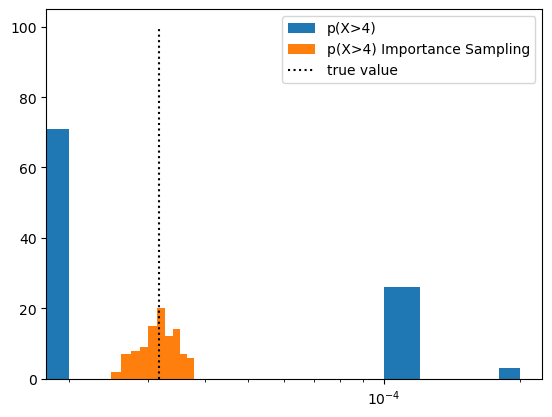

In [7]:
plt.hist(pthres_1, label=f'p(X>{thresh})');
plt.hist(pthres_4, label=f'p(X>{thresh}) Importance Sampling');
plt.xscale('log')
plt.vlines(x=(1-ndtr(thresh)), ymin=0, ymax=100, ls=':', color='black', label='true value');
plt.legend();

### Rejection sampling

Choose, $c$ such that for all $x$: $c Q^*(x) \ge P^*(x)$

  * generate $x$ from $Q^*(x)$
  * generate $u$ uniform from $[0,c Q^*(x)]$
  * if $u > P^*(x)$ reject $x$, otherwise accept $x$

The $R$ accepted samples $x^r$ are distributed as $p(x)=P^*(x)/Z_P$: the probability of a sample $x$ is $Q^*(x) \frac{P^*(x)}{cQ^*(x)}\propto P^*(x)$.
$$\hat{\Phi}=\frac{1}{R}\sum_{r=1}^R \phi(x^r)\rightarrow \int dx \phi(x) p(x)$$

#### An example of rejection sampling: Gamma distribution

Warning: in the following I used `k` for $c$ just for the sake of confusing readers.

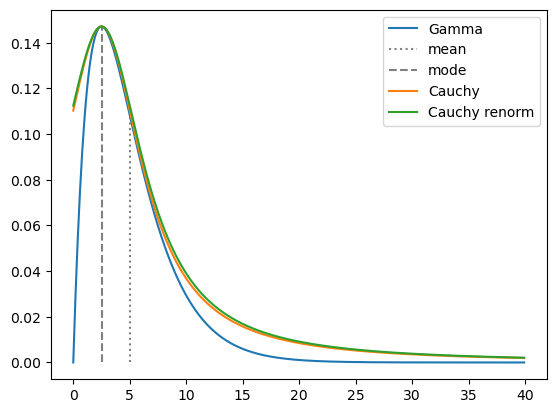

In [8]:
a = 2
b = 0.4
d = 40 # maximal element for sampling

xs = np.arange(0, d, 0.1)
plt.plot(xs, gamma.pdf(xs, a, scale=1/b), label="Gamma");
plt.vlines(x=a/b, ymin=0, ymax=gamma.pdf(a/b, a, scale=1/b), color='gray', ls=':', label="mean");
plt.vlines(x=(a-1)/b, ymin=0, ymax=gamma.pdf((a-1)/b, a, scale=1/b), color='gray', ls='--', label="mode");

# using plain Cauchy
C = (a - 1)/b
k = 2 # the choice of k here is not easy!
B = k/(np.pi * gamma.pdf((a-1)/b, a, scale=1/b))
plt.plot(xs, k/(1 + (xs - C)**2/B**2)/(np.pi*B), label="Cauchy");
# plt.plot(xs, k*cauchy.pdf(xs, loc=C, scale=B)) # just a check!

# using renormalized Cauchy
C = (a - 1)/b
B = 4.5
Z_renorm = B * (np.arctan((d-C)/B)-np.arctan(-C/B))
k_renorm = Z_renorm * gamma.pdf((a-1)/b, a, scale=1/b)
plt.plot(xs, k_renorm/(1 + (xs - C)**2/B**2)/Z_renorm, label="Cauchy renorm");
# plt.plot(xs, k*cauchy.pdf(xs, loc=C, scale=B)) # just a check!

plt.legend();

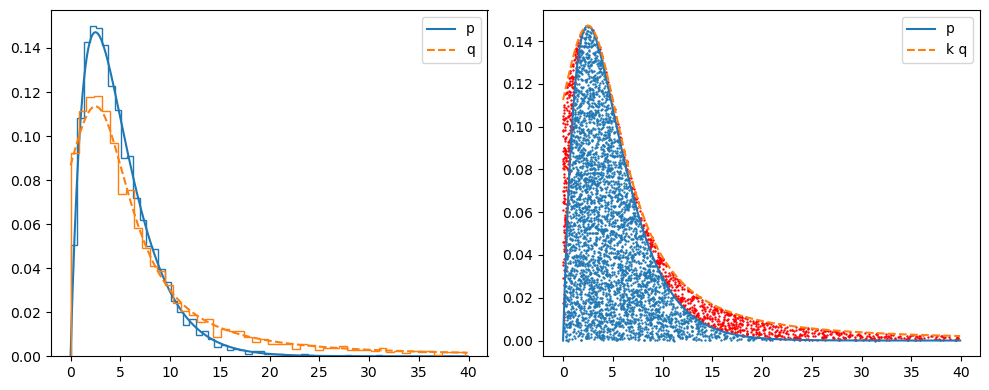

In [9]:
## using a renormalized Cauchy
num_samples = 5000
t_left = np.arctan(-C/B)
t_right = np.arctan((d-C)/B)
z = C + B * np.tan(np.random.rand(num_samples) * (t_right-t_left) + t_left)

pz = gamma.pdf(z, a, scale=1/b)
qz = 1/(1 + (z - C)**2/B**2)/Z_renorm
# sample homogeneously from 0 to k q(z)
u = k_renorm * qz * np.random.rand(num_samples)
accept = u <= pz
x = z[accept]
num_accept = len(x)

plt.figure(figsize=(10,4))
plt.subplot(121)
plt.hist(x, bins=50, density=True, histtype="step", color=color_cycle[0]);
plt.plot(xs, gamma.pdf(xs, a, scale=1/b), label="p", color=color_cycle[0]);

# note that the density of total samples is q(x)
plt.hist(z, bins=50, density=True, histtype="step", color=color_cycle[1]);
plt.plot(xs, 1/(1 + (xs - C)**2/B**2)/Z_renorm, '--', label="q", color=color_cycle[1]);
plt.legend();

# k q(x) can be visualized in a scatter plot
plt.subplot(122)
plt.scatter(z[accept], u[accept], marker='.', s=2, color=color_cycle[0]);
plt.scatter(z[~accept], u[~accept], marker='.', s=2, color="red");
plt.plot(xs, gamma.pdf(xs, a, scale=1/b), label="p");
plt.plot(xs, k_renorm/(1 + (xs - C)**2/B**2)/Z_renorm, '--', label="k q");
plt.legend();
plt.tight_layout();

#### Importance sampling in high dimensions

Importance sampling breaks down in high dimension because of the large variance of the sample weights $w(x)=\frac{p(x)}{q(x)}$.


The variance in $w$ depends on the difference between the distributions $q$ and $p$ [when $p=q$ one obviously has $w(x)=1$, i.e. weights have zero variance].

In high dimension, $\hat{\Phi}$ will be dominated by large contributions $w(x)\phi(x)$ induced by small $q(x)$: such contributions has low probability of occuring in the sample, and thus fluctuate wildly across realization of the importance sampler.

## *Bonus: Curse of dimensionality*

#### *Bonus: Geometry of spheres and Gaussians in high dimension*

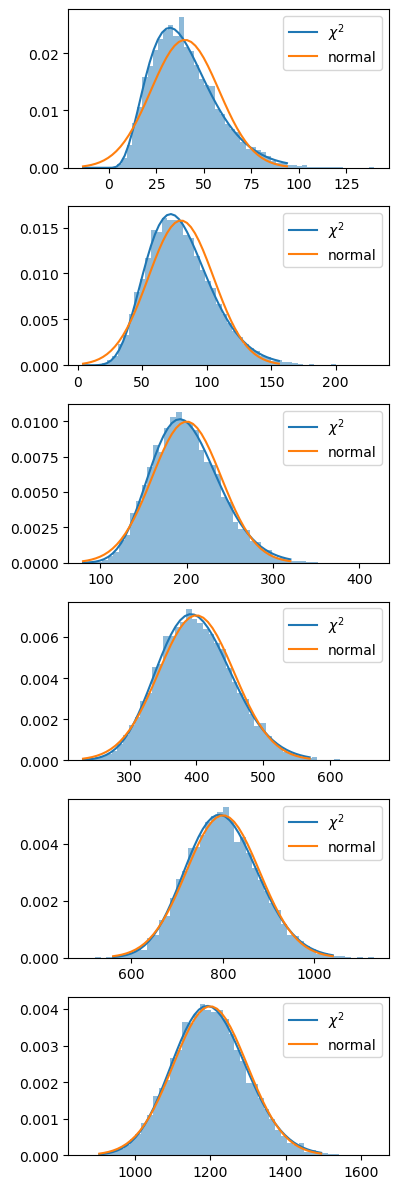

In [10]:
sigma = 2
num_sample = 10000

Ns = np.array([10, 20, 50, 100, 200, 300])

sqmean, sqvar = np.zeros(len(Ns)), np.zeros(len(Ns))

plt.figure(figsize=(4, 2 * len(Ns)))
count_fig = 0
for i, N in enumerate(Ns):
    sample = np.random.randn(num_sample, N) * sigma
    sqsample = (sample**2).sum(1)
    sqmean[i] = sqsample.mean()
    sqvar[i] = sqsample.var()

    count_fig += 1
    plt.subplot(len(Ns), 1, count_fig)
    plt.hist(sqsample, bins=50, density=True, alpha=0.5);
    mean = N * sigma**2
    var = 2 * N * sigma**4
    normal = multivariate_normal(mean, var)
    chisq = chi2(N, scale=sigma**2)
    xs = np.linspace(mean - 3 * np.sqrt(var), mean + 3 * np.sqrt(var))
    plt.plot(xs, chisq.pdf(xs), c=color_cycle[0], label='$χ^2$');
    plt.plot(xs, normal.pdf(xs), c=color_cycle[1], label='normal');
    plt.legend();
    
plt.tight_layout();

The previous plots show that in high dimensions the mass of a multidimensional Gaussian is concentrated in a shell or radius $\sqrt{N} \sigma$ [note that such region is pretty far away from the mode of the distribution]. Indeed, the quantity $\rho(x)=\sqrt{\sum_i x_i^2}$ has an approximately Gaussian distribution with mean and variance expressed by:

$$\rho^{2}\sim N\sigma^{2}\pm\sigma^{2}\sqrt{2N}$$

Visualize such relations in the following plot:

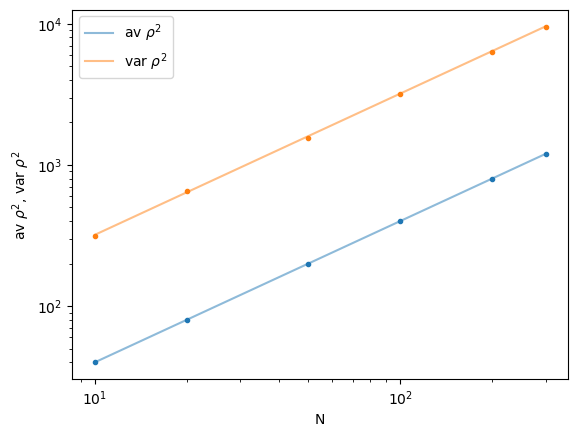

In [11]:
plt.plot(Ns, sqmean, '.', c=color_cycle[0]);
plt.plot(Ns, Ns * sigma**2, c=color_cycle[0], alpha=0.5, label="av $ρ^2$");
plt.plot(Ns, sqvar, '.', c=color_cycle[1]);
plt.plot(Ns, Ns * 2 * sigma**4, '-', c=color_cycle[1], alpha=0.5, label="var $ρ^2$")
plt.xscale('log')
plt.yscale('log')
plt.xlabel('N')
plt.ylabel('av $ρ^2$, var $ρ^2$');
plt.legend();

This concentration property extends to a sphere in $N$ dimension. Since the sphere volume scales with the radius $r$ as $r^N$, one has that for a small shell around the radius

$$\frac{r^{N}-\left(r-\epsilon\right)^{N}}{r^{N}}=1-\left(1-\frac{\epsilon}{r}\right)^{N}$$

thus all the volume is concentrated in the shell.

#### *Importance sampling in high dimensions (reprise)*

Suppose now we may want to sample from a uniform distribution $p(x)=p^*(x)/Z_P$ inside an $N$ dimensional sphere of radius $R_P$ using for $q$ a factorized Gaussian. We have:

$$p^{*}\left(x\right)=\theta\left(R_{P}-\rho\left(x\right)\right)$$

with $\theta$ the Heaviside function.

Suppose we are able to choose $\sigma$ in such a way that the shell lies inside the $R_P$ sphere. Samples from $q$ will have an approximate probability

$$\frac{1}{\left(2\pi\sigma^{2}\right)^{\frac{N}{2}}}\exp\left(-\frac{N}{2}\pm\sqrt{\frac{N}{2}}\right)$$

and thus a typical weight $w(x)=p^*(x)/q(x)$ equal to

$$\left(2\pi\sigma^{2}\right)^{\frac{N}{2}}\exp\left(\frac{N}{2}\pm\sqrt{\frac{N}{2}}\right)$$

We see that their fluctuations scale like $\exp(\sqrt{N})$.

In summary: even if we are able to make sure that $q$ generates samples from the typical set of $p$, the resulting weight will have a very large variance.

#### *Rejection sampling in high dimensions*

Rejection sampling is inefficient in high dimensions. Consider  $p(x)$ and $q(x)$ spherical Gaussians in $n$ dimensions with mean 0 and
$\sigma_q =1.01 \sigma_p$.

Since
$$q(x)=\left(\frac{1}{\sqrt{2\pi \sigma^2_q}}\right)^ne^{-\frac{1}{2\sigma_q^2}\sum_i x_i^2}\qquad p(x)=\left(\frac{1}{\sqrt{2\pi \sigma^2_p}}\right)^n e^{-\frac{1}{2\sigma_p^2}\sum_i x_i^2}$$then$$c=\frac{p(0)}{q(0)}=\left(\frac{\sigma_q}{\sigma_p}\right)^n=1.01^n$$

With $n=1000$ we find c=20.000. Thus volume under $c q$ is 20.000 times the volume under $p$. Therefore,
the acceptance rate = $\frac{\mbox{volume}~p}{\mbox{volume}~c q}=\frac{1}{c}$

## Markov processes and Markov Chain Monte Carlo (MCMC)

### Definition

Let $x$ take values in a finite set of states (e.g. binary vectors of length $n$: $2^n$ states), and let $p_t(x)$ be a probability distribution over states at time $t$.

A (discrete-time) **Markov process** is defined by a transition matrix $T(x'|x)$, the probability of jumping from state $x$ to state $x'$ in one step. Each column is a probability vector, $\sum_{x'} T(x'|x)=1$ (a **stochastic matrix**), and the distribution evolves as
$$p_{t+1}(x')=\sum_x T(x'|x)p_t(x)\qquad\text{i.e.}\qquad p_{t+1}=Tp_t$$

### Stationarity

In MCMC we build a Markov process $p_0 \to p_1 = T p_0 \to \ldots \to p_n=T^n p_0\to \ldots$ that converges to a **stationary distribution** $p_\infty$, invariant under the dynamics:
$$T p_\infty =p_\infty$$
i.e. $p_\infty$ is a (normalized) eigenvector of $T$ with eigenvalue 1. Such an eigenvalue always exists, since the normalization of the columns reads $\boldsymbol{1}^T T=\boldsymbol{1}^T$, and all eigenvalues satisfy $|\lambda|\leq1$.

* **Do all Markov chains have a stationary distribution?** Not necessarily (e.g. a random walk on an infinite set of states).
* **If it exists, will $T^n p_0$ converge to it?** Not necessarily: the process could be periodic.
* **Is it unique?** Not necessarily: this depends on the spectrum of $T$.

#### *Bonus: the spectrum of a stochastic matrix*

A "proof by example" that all eigenvalues lie in the unit disc: the eigenvalues of random column-stochastic matrices.

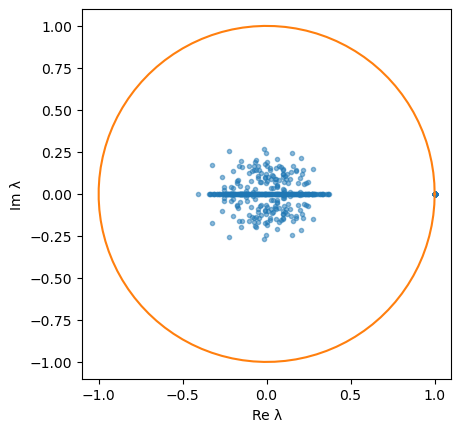

In [12]:
N = 5
num_samples = 100

# random column-stochastic matrices
Ts = np.random.rand(num_samples, N, N)
Ts = Ts / Ts.sum(1, keepdims=True)
eigs = np.linalg.eigvals(Ts)

plt.plot(np.real(eigs.flatten()), np.imag(eigs.flatten()), '.', alpha=0.5);
plt.gca().set_aspect('equal')
circle = np.exp(1j*np.linspace(0,2*np.pi,100))
plt.plot(np.real(circle), np.imag(circle));
plt.xlabel('Re λ')
plt.ylabel('Im λ');

If the Markov process is **irreducible** (every state can be reached from every other state with non-zero probability) and **aperiodic**, the eigenvalue $1$ is non-degenerate: the stationary distribution is unique and any initial condition converges to it (Perron-Frobenius). Eigenvalues with modulus close to 1 ($|\lambda|=1-\epsilon$, $\epsilon$ small) imply long convergence times.

### Detailed balance

The Markov process $T$ satisfies Detailed Balance (DB) if there exists $p$ such that
$$T(x|x')p(x')=T(x'|x)p(x)\quad\text{for all } x,x'.$$

The crucial property of DB is that:
$$\text{DB}\implies\text{stationarity}$$
since 
$$\sum_{x'}T\left(x|x'\right)p\left(x'\right)=\sum_{x'}T\left(x'|x\right)p\left(x\right)=p\left(x\right)$$
but in general
$$\text{DB}\nLeftarrow\text{stationarity}$$

#### Stationary distribution for a random walk on a lattice with reflecting boundaries

In [13]:
N = 20
num_steps = 1000
num_samples = 5000

x0 = 17
x = np.ones(num_samples) * x0
xs = np.zeros((num_steps, num_samples))
for t in range(num_steps):
    xs[t] = x
    x = x + 2 * np.random.randint(2, size=num_samples) - 1
    x = np.clip(x, 0, N)

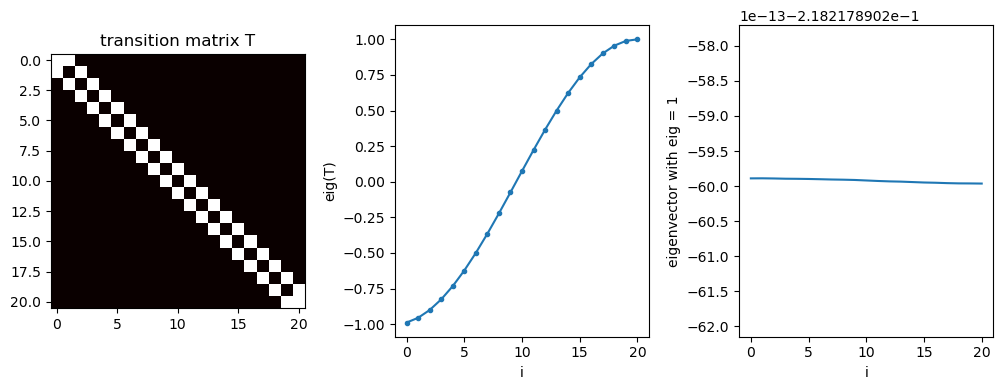

In [14]:
# define transition matrix
T = 0.5 * (np.eye(N+1, k=1) + np.eye(N+1, k=-1))
T[0,0] = 0.5
T[N,N] = 0.5

# compute eigenvalues and eigenvectors (use a function specific for hermitian matrices to directly get sorted eigevalues)
eigs, U = np.linalg.eigh(T)

plt.figure(figsize=(10,4))

plt.subplot(131)
plt.imshow(T, cmap='hot');
plt.title("transition matrix T")

plt.subplot(132)
plt.plot(eigs, '.-')
plt.xlabel('i')
plt.ylabel('eig(T)')

plt.subplot(133)
plt.plot(U[:,-1]);
plt.xlabel('i')
plt.ylabel('eigenvector with eig = 1')

plt.tight_layout();

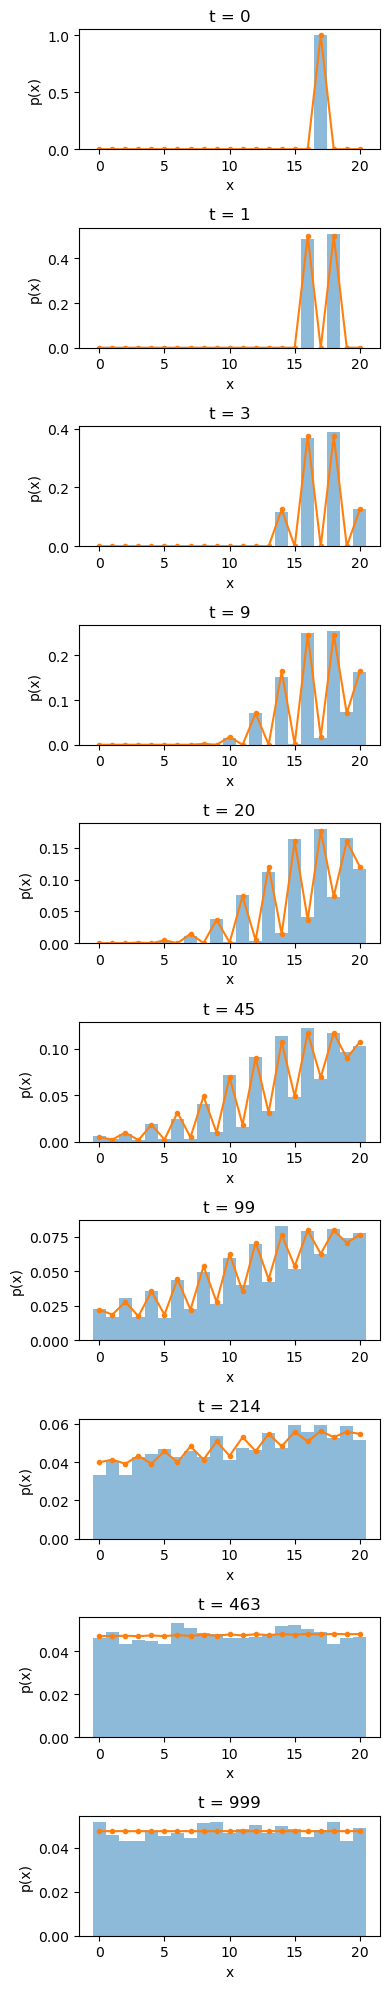

In [15]:
# evolve probability of states
p = np.zeros(N+1)
p[x0] = 1
ps = np.zeros((num_steps, N+1))
for t in range(num_steps):
    ps[t] = p
    p = T @ p

# visualize evolution of probability over states
num_to_show = 10
t_to_show = np.logspace(0, np.log10(num_steps), num_to_show, dtype=int) - 1

fig, axes = plt.subplots(num_to_show, figsize=(4, 2 * num_to_show))
for i, t in enumerate(t_to_show):
    axes[i].hist(xs[t], bins=np.arange(N+1+1)-0.5, density=True, alpha=0.5, label='data');
    axes[i].plot(ps[t], '.-', label='theory');
    axes[i].set_title(f't = {t}')
    axes[i].set_xlabel('x')
    axes[i].set_ylabel('p(x)');

plt.tight_layout();

## Markov chain Monte Carlo

### Metropolis-Hastings algorithm

Suppose we would like to sample from a distribution $p(x) = p^*(x)/Z$.

The Metropolis-Hastings (MH) algorithm is composed of two steps:
* **propose** a state $x'$ using a distribution $q(x'|x^r)$ that generally depends on the current sample $x^r$
* **accept** the state $x'$ with probability
  $$p_{a}\left(x',x^r\right)=\min\left(1,a\left(x',x^r\right)\right)$$
  $$a\left(x',x^{r}\right)=\frac{p^{*}\left(x'\right)q\left(x^{r}|x'\right)}{p^{*}\left(x^{r}\right)q\left(x'|x^{r}\right)}$$

  If $x'$ is accepted:
  $$x^{r+1}=x'$$
  else
  $$x^{r+1}=x^r$$

### Why MH works

We would like to prove that the MH transition probability $T(x'|x)$ satisfies detailed balance with respect to $p$.

Consider two states $x$, $x'$ and note that $a\left(x',x\right)=\frac{1}{a\left(x,x'\right)}$

Suppose $a_{x'x}\ge 1$. Then:

  * Given $x$ the probability to accept $x'$ is
    $$T(x'|x)=q(x'|x)$$
  * Given $x'$ the probability to accept $x$ is
    $$T(x|x')=q(x|x')a_{xx'}$$
    $$\frac{T(x'|x)}{T(x|x')}=a_{x'x}\frac{q(x'|x)}{q(x|x')}=\frac{p^*(x')}{p^*(x)} =\frac{p(x')}{p(x)},$$

The MH algorithm is thus an ergodic (aperiodic) Markov process that satisfies detailed balance: the process $T(x'|x)$ converges to $p(x)$.

## Gibbs sampling

At each time step, update a single variable $i$ using its conditional distribution from the target distribution $p(x)$.

$$p(x_i'|x_{\setminus i})$$

keeping all other elements $x'_{\setminus i}$ unchanged [$x_{\setminus i}$ is the vector of variables without $x_i$].

A Gibbs sampling step is a MH step with acceptance $a=1$. Indeed the update of the $x\to x'$ is described by
$$q(x'|x)=p(x'_i|x_{\setminus i})\delta_{x_{\setminus i},x'_{\setminus i}}$$
and for the acceptance:
$$a=\frac{p(x')}{p(x)}\frac{q(x|x')}{q(x'|x)}=\frac{p(x_i'|x'_{\setminus i})p(x'_{\setminus i})}{p(x_i|x_{\setminus i})p(x_{\setminus i})}\frac{p(x_i|x'_{\setminus i})}{p(x'_i|x_{\setminus i})}=\frac{p(x_i'|x_{\setminus i})}{p(x_i|x_{\setminus i})}\frac{p(x_i|x_{\setminus i})}{p(x'_i|x_{\setminus i})}=1$$
where we used $x'_{\setminus i}=x_{\setminus i}$.

## Spin models

### Why are we studying a magnetic system in a Machine Learning course?

* **Because**
* Paradigmatic model for the theory of phase transitions
* Close cousin of spin glass models: the physics of such systems is directly related to fundamental problems in neuroscience, machine learning, logic and computer science, e.g.
    - [Hopfield model](https://en.wikipedia.org/wiki/Hopfield_network)
    - [phase transitions in learning and computational problems](https://arxiv.org/abs/cond-mat/0104428)
    - [boolean satisfiability](https://en.wikipedia.org/wiki/Boolean_satisfiability_problem)
  
  and much more

### Exponential families and equilibrium statistical mechanics

The Maximum Entropy principle leads us to consider distributions in the exponential family:
$$
p(x)=\frac{1}{Z}\exp(\psi(x))
$$
Such distributions are ubiquitous both in Machine Learning and Physics [we usually set $\psi(x) = -\beta E(x)$ with $E(x)$ the Hamiltonian/energy function of the system and $\beta =1/\kappa T$ the inverse temperature].

Sampling from these distributions is crucial. On the other hand, optimization wrt a loss function $E(x)$ can be recast as the problem of finding the **ground state** of a system with Hamiltonian $E(x)$.

#### *Bonus: a refresher of basic relations*

The quantity $\log Z$ is useful as a generating functions for the cumulants of quantities of interest, which can be computed with appropriate differentiation. Let us take for example the energy $E$.

We have for the mean energy of the spin system $\langle E \rangle =\sum_x E(x) p(x)$:
$$-\frac{\partial \log Z}{\partial \beta}=-\frac{1}{Z}\frac{\partial Z}{\partial \beta}=\frac{1}{Z}\sum_x E(x) \exp(-\beta E(x))=\langle E \rangle$$

The variance of the energy can be computed similarly:
$$\frac{\partial^2 \log Z}{\partial \beta^2}=\frac{\partial}{\partial \beta} \left(\frac{1}{Z}\frac{\partial Z}{\partial \beta}\right)= -\frac{1}{Z^2} \left(\frac{\partial Z}{\partial \beta}\right)^2 +\frac{1}{Z}\frac{\partial^2 Z}{\partial \beta^2}$$
$$=-\langle E \rangle^2 + \frac{1}{Z}\sum_x E(x)^2\exp(-\beta E(x))=-\langle E \rangle^2+\langle E^2\rangle=\mathbb{V}(E)$$

Note that since $\partial_{T}=-\frac{1}{\kappa T^{2}}\partial_{\beta}$, the so-called **heat capacity** $C=\frac{\partial\left\langle E\right\rangle }{\partial T}$ is directly related to the previous expression, indeed:
$$
C=\frac{\partial\left\langle E\right\rangle }{\partial T}=-\frac{1}{\kappa T^{2}}\partial_{\beta}\left\langle E\right\rangle =\frac{1}{\kappa T^{2}}\partial^2_{\beta}\log Z=\frac{\mathbb{V}\left(E\right)}{\kappa T^{2}}
$$
Note the proportionality constant: large energy fluctuations at high temperatures nevertheless give vanishing heat capacity.

The log partition sum is proportional to the usual free energy in physics $F=-\frac{1}{\beta}\log Z$.

It is trivial to prove that:
$$F=\langle E \rangle-\frac{H}{\beta}\qquad$$
where $H$ is the Shannon entropy of the system:
$$H=-\sum_x p(x) \log p(x)$$

## The Ising model

The Ising model is a probability distribution over vectors of binary variables $x=(x_1,\ldots,x_N)$ with $x_i=\pm 1$:

$$p(x)=\frac{1}{Z}\exp \left(- \beta E(x)\right)\qquad E(x)=-\frac{1}{2}\sum_{i\ne j}J_{ij}x_ix_j-\sum_i h_i x_i$$

$$Z=\sum_x \exp(-\beta E(x))=\sum_{x_1}\ldots \sum_{x_N} \exp(-\beta E(x))$$

where in general $J_{ij}=J_{ji}$ and $J\neq 0$ when $i$ and $j$ are neighbours on a given (undirected) graph, and $0$ otherwise.

(Anti)Ferromagnetic interactions corresponds to ($J_{ij} = -J$) $J_{ij} = +J$.

Note: in what follows, we set $\kappa=1$ for simplicity. More in general, the quantity $\beta$ can be absorbed in the couplings $J_{ij}$.

### Metropolis-Hastings

We will be using proposals distributions where a single (randomly chosen) spin $x_i$ get flipped, namely:
$$
q\left(x'|x\right)=\frac{1}{N}\sum_{i=1}^{N}\prod_{j\neq i}\delta_{x'_{j},x{}_{j}}\delta_{x'_{j},-x{}_{j}}
$$
Each configuration $x$ has non-vanishing probability of jumping onto $N$ possible configurations $x'$ where a single spin has been flipped.

To make things more concrete, we could define the spin-flip operator $F_i$ in such a way that $F_i x$ is the vector of spins obtained by flipping spin $i$. We have:

$$q(F_i x|x)=\frac{1}{N}\qquad q(x|x)=0$$

The MH ratio for the transition from state $x$ to state $F_i x$ is thus

$$a \left(F_i x,x\right)=\frac{p^*(F_ix)}{p^*(x)}=\exp\left(- \beta \Delta E\right)$$

$$\Delta E = E(F_i x)-E(x)=2x_i \sum_{j\ne i} J_{ij}x_j$$

The energy decreases whenever the spin $x_i$ that gets flipped was previoulsy not aligned with its _local field_ $h_i=\sum_{j\ne i} J_{ij}x_j$.

### Gibbs sampling

The conditional probability for spin $i$ to flip only depends on its local field $h_i$ (make sure to do the math yourself!):

$$
p\left(x_{i}|h_{i}\right)=\frac{1}{1+e^{-2\beta x_{i} h_{i}}}
$$

### Measuring autocorrelation

During sampling $x_1,x_2,\ldots,x_N$ one obtains samples of the quantity of interest $Q_t=\phi(x_t)$.
One can estimate the autocorrelation
$$A(\tau) =\frac{\langle Q_tQ_{t+\tau}\rangle-\langle Q_t\rangle^2}{\langle Q_t^2\rangle-\langle Q_t\rangle^2}\propto e^{-\tau/\Theta}$$Note that $A(0)=1$. One expects for ergodic problems that for large $\tau$$$\langle Q_tQ_{t+\tau}\rangle=\langle Q_t\rangle\langle Q_{t+\tau}\rangle=\langle Q_t\rangle^2\qquad \lim_{\tau \to \infty}A(\tau)=0$$

$\Theta$ is the characteristic time on which the samples of the Markov process are correlated.
Thus, the effective number of independent samples is $N/\Theta$ [or better $\frac{N}{1+\Theta}$ to avoid infinities].

#### Visualize samples from a 32x32 2d Ising model at two different temperatures:

In [16]:
# example of an Ising model at T = 10
Video("figs/ising_size32_32_T10.mp4", embed=True)

In [17]:
# example of an Ising model at the critical temperature
Video("figs/ising_size32_32_T2.269.mp4", embed=True)

## Ferro-magnetic Ising model on a square lattice

We consider a square grid of $N=L\times L$ spins with periodic boundary conditions, each coupled to its 4 nearest neighbours with $J_{ij}=1$, and $h_i=0$. The system is run with MH on a temperature cycle (from high to low temperature and back, each chain started from the last sample of the previous one, as a check for equilibrium), with a burn-in of $100N$ steps followed by $S=1000$ samples, one every $100N$ steps.

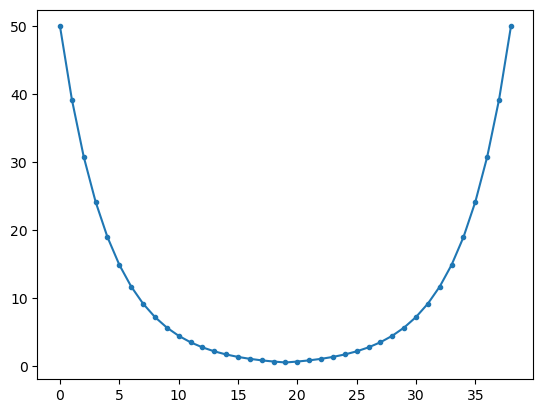

In [18]:
# load results for square grid with 100 spins
res_100 = np.loadtxt("data/ising2d_10_10.dat")

# this is the temperature protocol I used
Ts = res_100[:,0]
plt.plot(Ts, '.-');

### Energy and magnetization

* **Energy** of a configuration: $E(x)=-\sum_{\langle ij\rangle}x_ix_j$, where $\langle ij\rangle$ runs over the $2N$ nearest-neighbour pairs, each counted once. The energy per spin $E/N$ goes from $-2$ (all spins aligned) to $+2$. We measure its mean $\langle E \rangle=\sum_x p(x)E(x)$ and variance $\mathrm{Var}\,E=\langle E^2\rangle-\langle E \rangle^2$.
* **Magnetization** (per spin): $m(x)=\frac{1}{N}\sum_{i} x_i\in[-1,1]$. Since $E(x)=E(-x)$, $\langle m\rangle=0$ in a finite system, so we measure $\langle m^2\rangle$: $\approx 1/N$ at high temperature (nearly independent spins), $\approx 1$ at low temperature (close to one of the two ground states). Its drop marks the phase transition, at $T_c\approx2.269$ for $N\to\infty$.

The averages are estimated from the samples $x^1,\ldots,x^S$ of each chain: $\widehat{\langle E \rangle}=\frac{1}{S}\sum_{s} E(x^s)$, $\widehat{\mathrm{Var}\,E}=\frac{1}{S}\sum_{s} \left(E(x^s) - \widehat{\langle E \rangle}\right)^2$, $\widehat{\langle m^2\rangle} =\frac{1}{S}\sum_{s} m^2(x^s)$. The plots show $\langle E\rangle/N$, with error bars $\sqrt{\mathrm{Var}\,E}/N$, and $\langle m^2\rangle$.

### Mean energy and magnetization

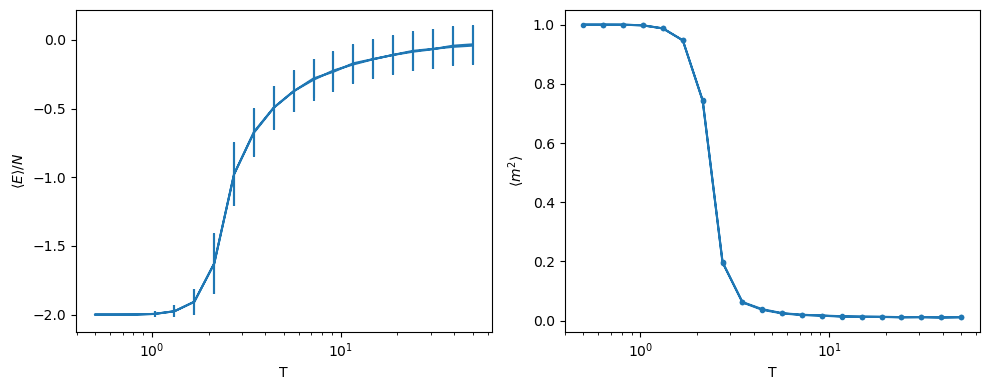

In [19]:
N = 100

plt.figure(figsize=(10,4))

plt.subplot(121)
plt.errorbar(Ts, y=res_100[:,1]/N, yerr=np.sqrt(res_100[:,2])/N)
plt.xscale('log');
plt.xlabel('T')
plt.ylabel(r'$\langle E\rangle/N$')

plt.subplot(122)
plt.plot(Ts, res_100[:,3], '.-')
plt.xscale('log');
plt.xlabel('T')
plt.ylabel(r'$\langle m^2\rangle$')

plt.tight_layout();

## A quick look at optimization

Exponential families connect sampling and optimization: minimizing a cost $E(x)$ means finding the **ground state** of $p(x)\propto e^{-\beta E(x)}$, on which the distribution concentrates as $\beta\to\infty$. Two examples of such energy functions over discrete variables:

* **Travelling salesman problem**: find the shortest tour visiting $n$ cities exactly once. The variables are the tours, i.e. cyclic permutations $\pi$ of the cities, with energy $E(\pi)=\sum_k d_{k\pi(k)}$, $d_{ij}$ the distance between cities $i$ and $j$.
* **Binary perceptron** (a quantized neural network): weights $w_i=\pm1$ and output $y(x)=\text{sign}(w\cdot x)$; on a data set $\{x^\mu,t^\mu\}_{\mu=1}^P$ with $t^\mu=\pm1$, the energy $E(w)=\sum_{\mu}\theta\left(-t^{\mu}w\cdot x^{\mu}\right)$ counts the misclassified examples.

**Simulated annealing** turns optimization into a sequence of sampling problems: run MCMC on $p_k(x)\propto e^{-E(x)/T_k}$ while slowly lowering the temperature $T_k$. Accepting some moves that increase the energy lets it escape the local minima where a greedy search gets stuck; if the temperature is lowered slowly enough, the global minimum is found with probability one (Hajek, 1988).

### An example of Simulated Annealing on a socially relevant travelling salesman problem

Illustration of the solution to the following TSP problem: find the best bike route for a tour of all bars in Nijmegen.

Distances are computed as shortest distances on bike routes on the map.

<center><img src="figs/tsp_nijmegen_map.png"></center>

The solution has been found running SA on a 33-dimensional instance (data from [OpenStreetMap](https://www.openstreetmap.org/relation/1201020)). Here is an illustration of the SA convergence:

<center><img src="figs/tsp_nijmegen_SA.gif"></center>

# <center>Assignments</center>

#### Ex 1.1 (MacKay Ex 29.13)

This exercise shows that importance sampling can fail even for Gaussian distributions in one dimension.

We wish to sample from a zero-mean one-dimensional Gaussian $p$ with variance $\sigma^2_p$, using a zero-mean Gaussian $q$ with variance $\sigma^2_q$. Compute the variance of the importance weights. What happens when $\sigma^2_q=\sigma^2_p / 2$? Reproduce Fig. 29.20 in MacKay's book.

#### Ex 1.2

In this exercise, you will study the effect of strong correlations between variables on the efficiency of MCMC.

Consider the 2-dimensional zero-mean Gaussian distribution with the following covariance matrix

$$
\left(\begin{array}{cc}
1 & \rho\\
\rho & 1
\end{array}\right)\qquad \rho=0.998
$$

1. Write a computer program to sample from this distribution using the Metropolis-Hastings algorithm with a Gaussian proposal of width $\sigma$. Study the acceptance ratio and how well the sampler covers the entire distribution by varying $\sigma$. Report the optimal values.
2. Show that the conditional distributions are Gaussian, $p(x_1|x_2)=\mathcal{N}(\rho x_2, 1-\rho^2)$ (and similarly for $x_2$), and write a Gibbs sampler for this distribution. How far does a Gibbs update move the state, compared to the size of the distribution along its long axis?
3. Compute the mean of this Gaussian distribution using both methods and compare the accuracy as a function of the computation time.

#### Ex 1.3

Implement MH sampling for the 2-d ferromagnetic Ising model with single spin flips on a $10\times10$ lattice ($N=100$, as in the lecture), and reproduce the plots in the section **Mean energy and magnetization**: energy per spin $\langle E\rangle/N$ (with error bars $\sqrt{\mathrm{Var}\,E}/N$) and $\langle m^2\rangle$ as a function of temperature, as defined in the section **Energy and magnetization** (temperature cycle, burn-in), zooming around the region where the magnetization drops.

Then implement Gibbs sampling (heat bath) for the same model and compare the two samplers at a few temperatures: do they give the same averages? Which one decorrelates the magnetization faster? To answer, record $Q_t=|m(x_t)|$ after every sweep ($N$ proposed flips) and estimate its autocorrelation function
$$A(\tau)=\frac{\langle Q_tQ_{t+\tau}\rangle-\langle Q_t\rangle^2}{\langle Q_t^2\rangle-\langle Q_t\rangle^2}$$
which starts at $A(0)=1$ and decays to zero, roughly as $e^{-\tau/\Theta}$: the faster sampler has the shorter correlation time $\Theta$, i.e. more independent samples per sweep.

#### Ex 1.4

##### Setting

Consider the learning problem for logistic regression of Part 1 (see also MacKay chapters 39 and 41). Our aim is to sample from the distribution $p\left(w|D, \alpha\right)$ as given by MacKay Eqs. 41.8-10. Let us recap it in the following (note: the notation is slightly different from the book).

**Data set**:
$$D=\{x^\mu,t^\mu\}$$

with $t^\mu\in\{0,1\}$ and $\mu=1,\ldots,P$ [this is the model of Part 1, with labels $t=\pm1$ written as $t\in\{1,0\}$, and a bias $w_0$].

**Conditional model** (probability of label $t$ given $x$):

$$p(t=1|x,w)=\sigma(\vec{w}\cdot\vec{x})$$
$$\vec{w}\cdot\vec{x}=w_0+w_1 x_1 +w_2 x_2$$
$$\sigma(h)=\frac{1}{1+\exp(-h)}$$

**Likelihood**:
$$p(D|w)=\prod_\mu p(t^\mu|x^\mu,w)=e^{-\mathcal{E}(w)}\qquad \mathcal{E}(w)=-\sum_\mu \log p(t^\mu|x^\mu,w)$$

**Prior**:
$$p(w)=\frac{e^{-\alpha R(w)}}{Z_w(\alpha)}\qquad R(w)=\frac{1}{2}\sum_i w_i^2$$

**Posterior**:
$$p(w|D)=\frac{p(D|w)p(w)}{p(D)} \propto e^{-L(w)}$$
with
$$L(w)=\mathcal{E}(w)+\alpha R(w)$$

##### Exercise

Implement MH to sample from the distribution $p\left(w|D, \alpha\right)$, using the data of MacKay Fig. 41.1: inputs $(5,5)$, $(-4,-2)$, $(1.5,1.5)$, $(-1,1)$, $(1.5,3.5)$, $(-9,0)$ with labels $1,0,0,1,1,0$, and $\alpha=0.01$.
Reproduce plots similar to MacKay Fig. 41.5 and estimate the burn-in time that is required before the sampler reaches the equilibrium distribution.

Investigate the acceptance ratio and try to optimize it by varying the width of the proposal distribution. Use the samples to compute the Bayesian predictive probability $p(t=1|x,D)$ on a grid of inputs and compare it with the prediction of the most probable weights.